# BrainScan: Brain Tumor MRI Classification

## 1. Project Overview

BrainScan is a computer vision project that aims to classify brain MRI images into four categories:

- **Glioma**
- **Meningioma**
- **No tumor**
- **Pituitary tumor**

The final objective is to train a convolutional neural network (CNN) that can learn visual patterns from the MRI images. This notebook documents the first stage of the project: dataset exploration, integrity validation, visual inspection, and preparation for a consistent model input pipeline.

### Notebook Objectives

This notebook will:

1. Confirm the dataset structure and available classes.
2. Count images and inspect the `Tr-` and `Te-` filename prefixes.
3. Detect unreadable images and unsupported files.
4. Visualize representative samples from each class.
5. Analyze image dimensions and aspect ratios.
6. Identify the preprocessing decisions required before model training.

> **Current status:** dataset auditing and preprocessing analysis are complete. Model training and evaluation will be addressed in a later notebook.

In [ ]:
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time

from pathlib import Path
from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from keras import layers, models

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
)

I0000 00:00:1792263250.107215    4460 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792263250.267042    4460 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792263251.162659    4460 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "Data"

IMAGE_SIZE = (224, 224)
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

VALIDATION_SIZE = 0.15

RANDOM_STATE = 42

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Dataset exists:", DATA_DIR.exists())
print("Image size:", IMAGE_SIZE)
print("Supported extensions:", VALID_EXTENSIONS)


Project directory: /home/houssam/Documents/brief-4
Dataset directory: /home/houssam/Documents/brief-4/Data
Dataset exists: True
Image size: (224, 224)
Supported extensions: {'.jpg', '.png', '.jpeg', '.bmp'}


## 2. Dataset Exploration

Before preprocessing, we inspect the dataset structure and verify that folder names can be used as class labels.

The exploration covers:

- Available class directories.
- Number of files and supported images in each class.
- `Tr-` and `Te-` filename prefixes.
- Potential unsupported or unreadable files.

This step helps prevent incorrect labels and makes the eventual train/validation/test split easier to reproduce.

In [3]:
class_dirs = sorted(
    folder for folder in DATA_DIR.iterdir()
    if folder.is_dir()
)

print("Number of classes:", len(class_dirs))

Number of classes: 4


In [4]:
count = 0

for folder in class_dirs:
    files = [file for file in folder.iterdir() if file.is_file()]

    images = [file for file in files if file.suffix.lower() in VALID_EXTENSIONS]

    prefixes = Counter(
        file.name[:3] for file in images if file.name.startswith(("Tr-", "Te-"))
    )

    count += len(files)

    print(f"Class: {folder.name}")
    print(f"  Total files: {len(files)}")
    print(f"  Supported images: {len(images)}")
    print(f"  Training prefix (Tr-): {prefixes['Tr-']}")
    print(f"  Testing prefix (Te-): {prefixes['Te-']}")
    print()

print(f"Total of images : {count}")

Class: glioma
  Total files: 1621
  Supported images: 1621
  Training prefix (Tr-): 1321
  Testing prefix (Te-): 300

Class: meningioma
  Total files: 1645
  Supported images: 1645
  Training prefix (Tr-): 1339
  Testing prefix (Te-): 306

Class: notumor
  Total files: 2000
  Supported images: 2000
  Training prefix (Tr-): 1595
  Testing prefix (Te-): 405

Class: pituitary
  Total files: 1757
  Supported images: 1757
  Training prefix (Tr-): 1457
  Testing prefix (Te-): 300

Total of images : 7023


### 2.1 Image Integrity Check

Every supported image is opened with OpenCV before it is passed to a preprocessing pipeline. If `cv2.imread` returns `None`, the file cannot be decoded reliably and should be excluded or repaired before training.

A clean integrity check should report **0 unreadable images** and **0 unsupported files**.

In [5]:

corrupted_images = []
unsupported_files = []
total_images = 0

for folder in class_dirs:
    for file in folder.iterdir():
        if not file.is_file():
            continue

        if file.suffix.lower() not in VALID_EXTENSIONS:
            unsupported_files.append(str(file))
            continue

        total_images += 1
        image = cv2.imread(str(file))

        if image is None:
            corrupted_images.append(str(file))

print("Total supported image files:", total_images)
print("Unreadable images:", len(corrupted_images))
print("Unsupported files:", len(unsupported_files))

if corrupted_images:
    print("\nExamples of unreadable images:")
    for path in corrupted_images[:10]:
        print(path)

if unsupported_files:
    print("\nExamples of unsupported files:")
    for path in unsupported_files[:10]:
        print(path)


Total supported image files: 7023
Unreadable images: 0
Unsupported files: 0


## 3. Visual Data Exploration

Representative images are sampled from every class using the fixed random seed defined above. This makes the visual review reproducible while keeping the plot small enough to inspect.

The samples are used to:

- Check that images match their directory labels.
- Compare the visual appearance of the four classes.
- Observe color, quality, and presentation differences.
- Identify unusual images that may need additional preprocessing.

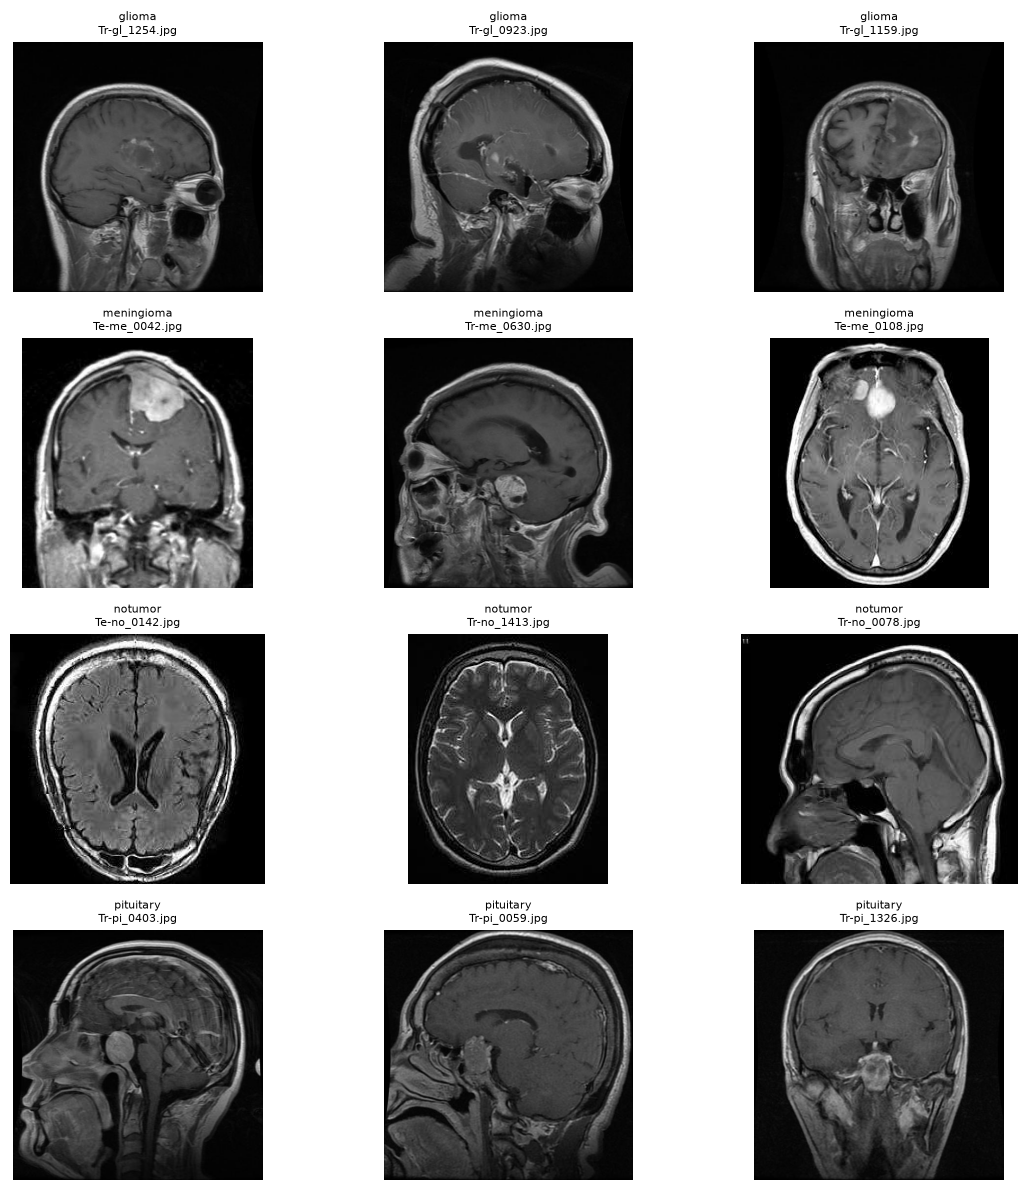

In [6]:
random.seed(RANDOM_STATE)

NUM_SAMPLES = 3

fig, axes = plt.subplots(
    nrows=len(class_dirs),
    ncols=NUM_SAMPLES,
    figsize=(12, 12)
)

for row, folder in enumerate(class_dirs):
    image_paths = [
        file for file in folder.iterdir()
        if file.is_file()
        and file.suffix.lower() in VALID_EXTENSIONS
    ]

    selected_paths = random.sample(
        image_paths,
        k=min(NUM_SAMPLES, len(image_paths))
    )

    for col, image_path in enumerate(selected_paths):
        image = cv2.imread(str(image_path))

        axes[row, col].imshow(image)
        axes[row, col].set_title(
            f"{folder.name}\n{image_path.name}",
            fontsize=8
        )
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()


In [7]:
image_shapes = Counter()
unusual_dimensions = []

for folder in class_dirs:
    for image_path in folder.iterdir():

        image = cv2.imread(str(image_path))

        if image is not None:
            height, width = image.shape[:2]
            image_shapes[(height, width)] += 1

print("Number of unique image dimensions:", len(image_shapes))
print("\nMost common dimensions:")

for shape, count in image_shapes.most_common(10):
    print(f"{shape}: {count} images")

print("\nMinimum width:", min(w for h, w in image_shapes))
print("Maximum width:", max(w for h, w in image_shapes))
print("Minimum height:", min(h for h, w in image_shapes))
print("Maximum height:", max(h for h, w in image_shapes))

Number of unique image dimensions: 387

Most common dimensions:
(512, 512): 4742 images
(225, 225): 332 images
(630, 630): 90 images
(236, 236): 81 images
(251, 201): 58 images
(221, 228): 51 images
(217, 232): 50 images
(168, 300): 49 images
(442, 442): 46 images
(198, 150): 44 images

Minimum width: 150
Maximum width: 1920
Minimum height: 168
Maximum height: 1446


## 4. Image Dimension Analysis

The images do not all share the same spatial dimensions. The most common shape is `512 x 512`, but the dataset also contains many smaller and non-square images.

A CNN requires a consistent input shape for batched training, so the images will be resized to `224 x 224` during preprocessing. Because the measured aspect ratios range from `0.645` to `1.786`, the next pipeline should compare direct resizing with a distortion-aware strategy such as padding or center cropping.

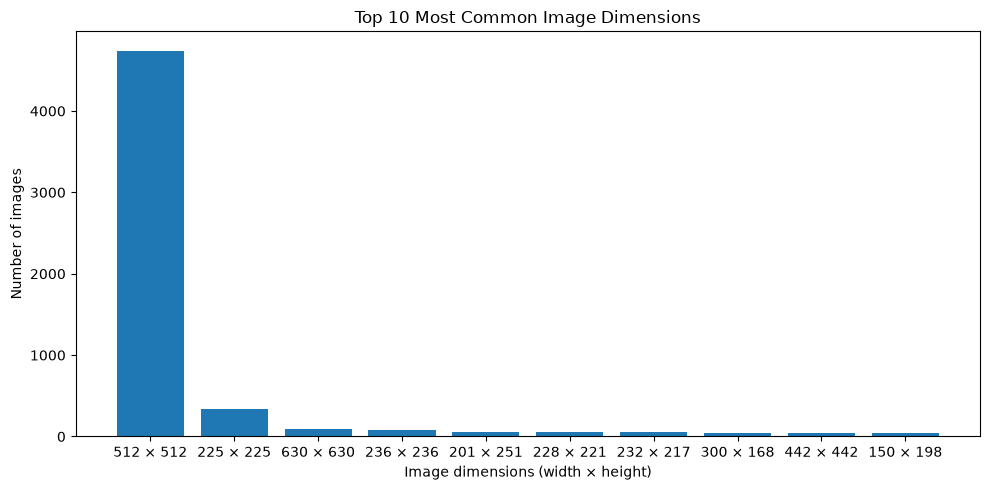

In [8]:
top_shapes = image_shapes.most_common(10)

shape_labels = [f"{width} × {height}" for (height, width), count in top_shapes]

shape_counts = [count for shape, count in top_shapes]

plt.figure(figsize=(10, 5))
plt.bar(shape_labels, shape_counts)
plt.title("Top 10 Most Common Image Dimensions")
plt.xlabel("Image dimensions (width × height)")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

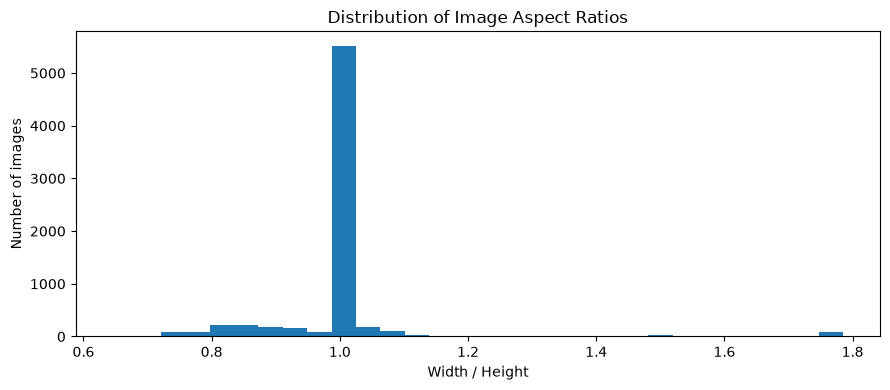

Minimum aspect ratio: 0.645
Maximum aspect ratio: 1.786


In [9]:

aspect_ratios = []

for (height, width), count in image_shapes.items():
    aspect_ratios.extend([width / height] * count)

plt.figure(figsize=(9, 4))
plt.hist(aspect_ratios, bins=30)
plt.title("Distribution of Image Aspect Ratios")
plt.xlabel("Width / Height")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()

print("Minimum aspect ratio:", round(min(aspect_ratios), 3))
print("Maximum aspect ratio:", round(max(aspect_ratios), 3))

## 5. Comparing Image Resizing Strategies

Direct resizing forces every image into a fixed square, which may distort images with non-square aspect ratios.

Aspect-ratio-preserving resizing scales each image proportionally and adds padding to reach the target dimensions. This reduces geometric distortion, although the padding introduces additional background pixels.

We will visually compare both approaches before selecting the preprocessing strategy.

In [10]:

def resize_direct(image, size=(224, 224)):
    return cv2.resize(image, size, interpolation=cv2.INTER_AREA)


In [11]:
def resize_with_padding(image, size=(224, 224)):
    target_width, target_height = size
    height, width = image.shape[:2]

    scale = min(target_width / width, target_height / height)

    new_width = int(round(width * scale))
    new_height = int(round(height * scale))

    resized = cv2.resize(
        image,
        (new_width, new_height),
        interpolation=cv2.INTER_AREA
    )

    canvas = np.zeros(
        (target_height, target_width, 3),
        dtype=np.uint8
    )

    x_offset = (target_width - new_width) // 2
    y_offset = (target_height - new_height) // 2

    canvas[
        y_offset:y_offset + new_height,
        x_offset:x_offset + new_width
    ] = resized

    return canvas

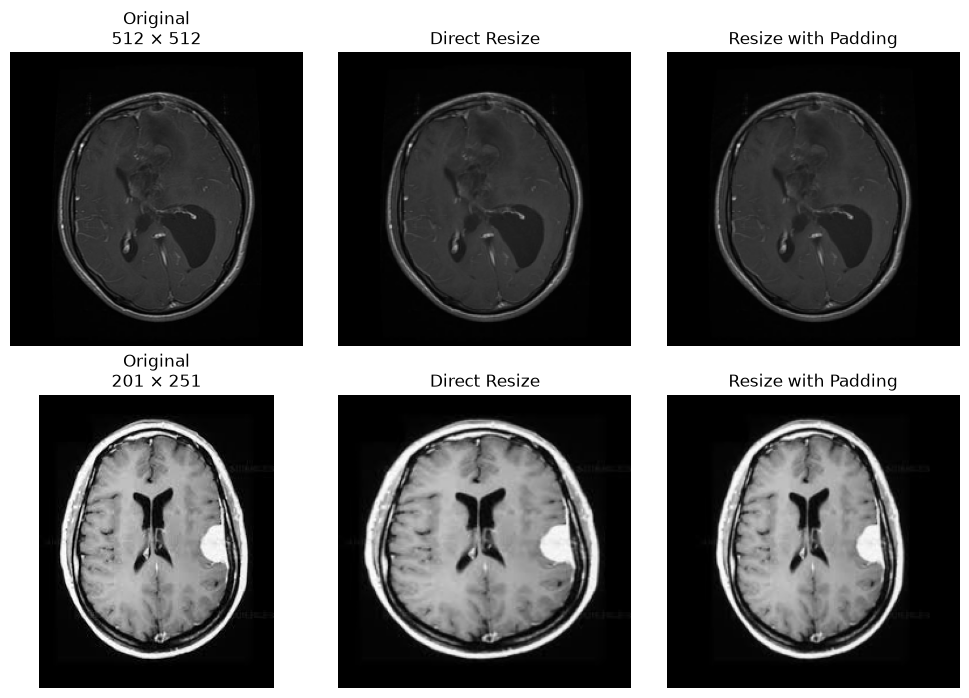

In [12]:
all_image_paths = [
    file
    for folder in class_dirs
    for file in folder.iterdir()
    if file.is_file() and file.suffix.lower() in VALID_EXTENSIONS
]

square_path = next(
    path
    for path in all_image_paths
    if (img := cv2.imread(str(path))) is not None and img.shape[0] == img.shape[1]
)

nonsquare_path = next(
    path
    for path in all_image_paths
    if (img := cv2.imread(str(path))) is not None and img.shape[0] != img.shape[1]
)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

for row, path in enumerate([square_path, nonsquare_path]):
    image = cv2.imread(str(path))

    direct = resize_direct(image, IMAGE_SIZE)
    padded = resize_with_padding(image, IMAGE_SIZE)

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original\n{image.shape[1]} × {image.shape[0]}")

    axes[row, 1].imshow(direct)
    axes[row, 1].set_title("Direct Resize")

    axes[row, 2].imshow(padded)
    axes[row, 2].set_title("Resize with Padding")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

## 6. Image Loading and Preprocessing

Based on the visual comparison, we select aspect-ratio-preserving resizing with padding.

Each image will be:
- Loaded using OpenCV.
- Converted from BGR to RGB.
- Resized to 224 × 224 while preserving its aspect ratio.
- Associated with its class label and original dataset split.

The original training and testing partitions will remain separate. Validation data will be selected from the training partition only.

In [13]:
images = []
labels = []
splits = []
image_paths = []
failed_images = []

for folder in class_dirs:
    for path in folder.iterdir():
        if not path.is_file() or path.suffix.lower() not in VALID_EXTENSIONS:
            continue

        if path.name.startswith("Tr-"):
            split = "train"
        elif path.name.startswith("Te-"):
            split = "test"
        else:
            failed_images.append((str(path), "Unknown filename prefix"))
            continue

        image = cv2.imread(str(path))

        if image is None:
            failed_images.append((str(path), "Unreadable image"))
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        image = resize_with_padding(image, IMAGE_SIZE)

        images.append(image)
        labels.append(folder.name)
        splits.append(split)
        image_paths.append(str(path))

X = np.stack(images)
y = np.array(labels)
splits = np.array(splits)
image_paths = np.array(image_paths)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print(f"Training images: {np.sum(splits == "train") / X.shape[0] * 100:.2f}%")
print(f"Testing images: {np.sum(splits == "test") / X.shape[0] * 100:.2f}%")
print("Failed or unclassified images:", len(failed_images))
print("Image data type:", X.dtype)
print("Pixel value range:", X.min(), "to", X.max())

Images shape: (7023, 224, 224, 3)
Labels shape: (7023,)
Training images: 81.33%
Testing images: 18.67%
Failed or unclassified images: 0
Image data type: uint8
Pixel value range: 0 to 255


## 7. Dataset Validation

After loading and resizing the images, we verify the dataset structure, split sizes, class distribution, and pixel values.

These checks help confirm that preprocessing did not discard images or mix the original training and testing partitions.

In [14]:
print("Dataset shape:", X.shape)
print("Labels shape:", y.shape)

train_mask = splits == "train"
test_mask = splits == "test"

print("\nDataset split:")
print("Training images:", np.sum(train_mask))
print("Testing images:", np.sum(test_mask))
print("Total images:", len(X))

print("\nSplit percentages:")
print(f"Training: {train_mask.mean() * 100:.2f}%")
print(f"Testing: {test_mask.mean() * 100:.2f}%")

for split_name, mask in [("Training", train_mask), ("Testing", test_mask)]:
    print(f"\n{split_name} class distribution:")
    class_counts = Counter(y[mask])

    for class_name in sorted(class_counts):
        print(f"{class_name}: {class_counts[class_name]}")

print("\nData type:", X.dtype)
print("Pixel range:", X.min(), "to", X.max())
print("Failed images:", len(failed_images))

assert X.shape == (7023, 224, 224, 3)
assert len(y) == len(splits) == len(image_paths)
assert np.sum(train_mask) == 5712
assert np.sum(test_mask) == 1311
assert len(failed_images) == 0

print("\nAll validation checks passed.")

Dataset shape: (7023, 224, 224, 3)
Labels shape: (7023,)

Dataset split:
Training images: 5712
Testing images: 1311
Total images: 7023

Split percentages:
Training: 81.33%
Testing: 18.67%

Training class distribution:
glioma: 1321
meningioma: 1339
notumor: 1595
pituitary: 1457

Testing class distribution:
glioma: 300
meningioma: 306
notumor: 405
pituitary: 300

Data type: uint8
Pixel range: 0 to 255
Failed images: 0

All validation checks passed.


In [15]:

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

print("Class mapping:")

for index, class_name in enumerate(label_encoder.classes_):
    print(f"{class_name} -> {index}")

print("\nEncoded labels shape:", y_encoded.shape)
print("Unique encoded labels:", np.unique(y_encoded))

Class mapping:
glioma -> 0
meningioma -> 1
notumor -> 2
pituitary -> 3

Encoded labels shape: (7023,)
Unique encoded labels: [0 1 2 3]


## 8. Training and Validation Split

The original test set remains untouched and independent from model development.

We split the original training set into training and validation subsets using stratified sampling. Stratification preserves the approximate class proportions in both subsets.

The validation set will be used to monitor model performance and tune hyperparameters. The test set will only be used for final evaluation.

In [16]:
train_pool_mask = splits == "train"
test_mask = splits == "test"

X_train_pool = X[train_pool_mask]
y_train_pool = y_encoded[train_pool_mask]

X_test = X[test_mask]
y_test = y_encoded[test_mask]

X_train, X_val, y_train, y_val = train_test_split(
    X_train_pool,
    y_train_pool,
    test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE,
    stratify=y_train_pool,
)

print("Training set:", X_train.shape, y_train.shape)
print("Validation set:", X_val.shape, y_val.shape)
print("Test set:", X_test.shape, y_test.shape)

print("\nClass distribution:")

for name, labels in [("Training", y_train), ("Validation", y_val), ("Testing", y_test)]:
    counts = Counter(labels)
    print(f"\n{name}:")

    for index, class_name in enumerate(label_encoder.classes_):
        print(f"  {class_name}: {counts[index]}")

assert len(X_train) + len(X_val) == len(X_train_pool)
assert len(X_train) + len(X_val) + len(X_test) == len(X)

print("\nSplit verification passed.")

Training set: (4855, 224, 224, 3) (4855,)
Validation set: (857, 224, 224, 3) (857,)
Test set: (1311, 224, 224, 3) (1311,)

Class distribution:

Training:
  glioma: 1123
  meningioma: 1138
  notumor: 1356
  pituitary: 1238

Validation:
  glioma: 198
  meningioma: 201
  notumor: 239
  pituitary: 219

Testing:
  glioma: 300
  meningioma: 306
  notumor: 405
  pituitary: 300

Split verification passed.


In [17]:

X_train = X_train.astype(np.float64) / 255.0
X_val = X_val.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

print("Training dtype:", X_train.dtype)
print("Training range:", X_train.min(), "to", X_train.max())

print("Validation dtype:", X_val.dtype)
print("Validation range:", X_val.min(), "to", X_val.max())

print("Testing dtype:", X_test.dtype)
print("Testing range:", X_test.min(), "to", X_test.max())


Training dtype: float64
Training range: 0.0 to 1.0
Validation dtype: float64
Validation range: 0.0 to 1.0
Testing dtype: float64
Testing range: 0.0 to 1.0


## 9. Final Dataset Validation

In this section, we verify the final dataset shapes, class distributions, normalized pixel values, and sample images.

These checks help ensure that the data is correctly prepared before CNN training.

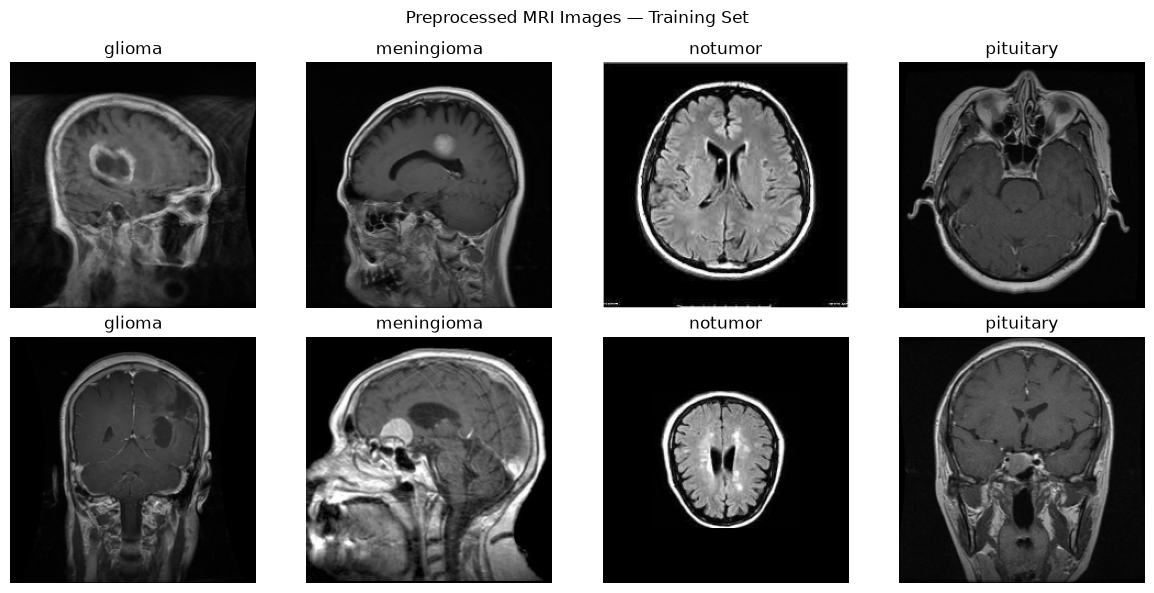

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for class_index, class_name in enumerate(label_encoder.classes_):
    indices = np.flatnonzero(y_train == class_index)

    selected_indices = indices[:2]

    for row, sample_index in enumerate(selected_indices):
        axes[row, class_index].imshow(X_train[sample_index])
        axes[row, class_index].set_title(class_name)
        axes[row, class_index].axis("off")

plt.suptitle("Preprocessed MRI Images — Training Set")
plt.tight_layout()
plt.show()

## 10. Class Distribution and Balance Analysis

Before designing the CNN, we inspect the number of images in each class.

This analysis helps identify potential class imbalance. We will evaluate the distribution in the training set because it is the data used to fit the model.

If the classes are sufficiently balanced, we can start without resampling or class weighting.

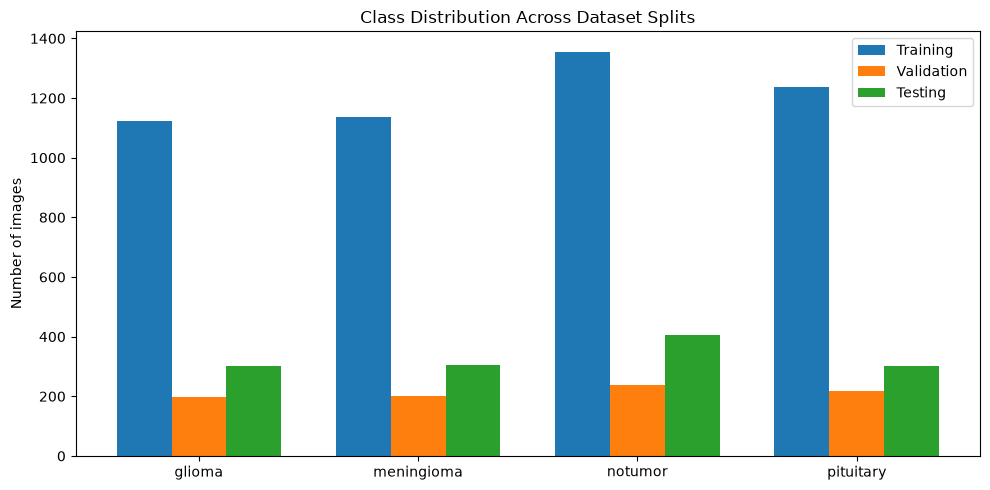

In [19]:
class_names = list(label_encoder.classes_)

train_counts = [int(np.sum(y_train == i)) for i in range(len(class_names))]

val_counts = [int(np.sum(y_val == i)) for i in range(len(class_names))]

test_counts = [int(np.sum(y_test == i)) for i in range(len(class_names))]

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(x - width, train_counts, width, label="Training")
plt.bar(x, val_counts, width, label="Validation")
plt.bar(x + width, test_counts, width, label="Testing")

plt.xticks(x, class_names)
plt.ylabel("Number of images")
plt.title("Class Distribution Across Dataset Splits")
plt.legend()
plt.tight_layout()
plt.show()

## 11. CNN Model Architecture

We will build a baseline Convolutional Neural Network using TensorFlow and Keras.

The architecture contains:

- **Conv2D:** learns spatial features such as edges, textures, and image patterns.
- **MaxPooling2D:** reduces the spatial dimensions of feature maps.
- **Dropout:** helps reduce overfitting during training.
- **GlobalAveragePooling2D:** summarizes feature maps with fewer parameters than Flatten in this architecture.
- **Dense:** combines learned features for classification.
- **Softmax:** produces probabilities for the four target classes.

This baseline provides a starting point for evaluating model performance before hyperparameter tuning.

In [20]:
INPUT_SHAPE = (224, 224, 3)
NUM_CLASSES = len(class_names)

tf.keras.utils.set_random_seed(RANDOM_STATE)

model = models.Sequential(
    [
        layers.Input(shape=INPUT_SHAPE),
        # Block 1
        layers.Conv2D(32, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        # Block 2
        layers.Conv2D(64, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        # Block 3
        layers.Conv2D(128, kernel_size=3, padding="same", activation="relu"),
        layers.MaxPooling2D(pool_size=2),
        # Classification head
        layers.GlobalAveragePooling2D(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(NUM_CLASSES, activation="softmax"),
    ],
    name="BrainScan_CNN",
)

model.summary()

I0000 00:00:1792263272.937717    4460 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 6129 MB memory:  -> device: 0, name: NVIDIA RTX 2000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Model: "BrainScan_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

## 12. Model Compilation

We compile the CNN using the Adam optimizer and sparse categorical cross-entropy.

Because class labels are encoded as integers from 0 to 3, `sparse_categorical_crossentropy` is appropriate. The accuracy metric will track the proportion of correctly classified images during training and validation.

In [21]:
LEARNING_RATE = 0.001

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "BrainScan_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
EPOCHS = 50
BATCH_SIZE = 32

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

checkpoint_path = MODEL_DIR / "brainscan_best.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(checkpoint_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
    verbose=1
)

training_seconds = time.time() - start_time

print(f"\nTraining duration: {training_seconds:.2f} seconds")
print(f"Training duration: {training_seconds / 60:.2f} minutes")
print("Best model path:", checkpoint_path)


Epoch 1/50


I0000 00:00:1792263275.952000    4460 service.cc:154] XLA service 0x564450d0a8f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792263275.952019    4460 service.cc:170]   StreamExecutor [0]: NVIDIA RTX 2000 Ada Generation Laptop GPU, Compute Capability 8.9 (Driver: 13.4.0[615.78.8]; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792263275.974848    4460 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792263276.346932    4460 cuda_dnn.cc:442] Loaded cuDNN version 92700
I0000 00:00:1792263277.538518    5369 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 12 bytes spill stores, 12 bytes spill loads



  3/152 ━━━━━━━━━━━━━━━━━━━━ 6s 46ms/step - accuracy: 0.2292 - loss: 1.3851 

I0000 00:00:1792263280.536565    4460 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


151/152 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.4269 - loss: 1.1752

I0000 00:00:1792263288.373014    5876 subprocess_compilation.cc:349] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_12', 12 bytes spill stores, 12 bytes spill loads



152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.4280 - loss: 1.1736
Epoch 1: val_loss improved from None to 0.93522, saving model to /home/houssam/Documents/brief-4/models/brainscan_best.keras

Epoch 1: finished saving model to /home/houssam/Documents/brief-4/models/brainscan_best.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 19s 95ms/step - accuracy: 0.4280 - loss: 1.1736 - val_accuracy: 0.6196 - val_loss: 0.9352 - learning_rate: 0.0010
Epoch 2/50
152/152 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6260 - loss: 0.9270
Epoch 2: val_loss improved from 0.93522 to 0.88387, saving model to /home/houssam/Documents/brief-4/models/brainscan_best.keras

Epoch 2: finished saving model to /home/houssam/Documents/brief-4/models/brainscan_best.keras
152/152 ━━━━━━━━━━━━━━━━━━━━ 7s 48ms/step - accuracy: 0.6260 - loss: 0.9270 - val_accuracy: 0.6453 - val_loss: 0.8839 - learning_rate: 0.0010
Epoch 3/50
151/152 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.6616 - loss: 0.8518
Epoch 3: val_loss impr

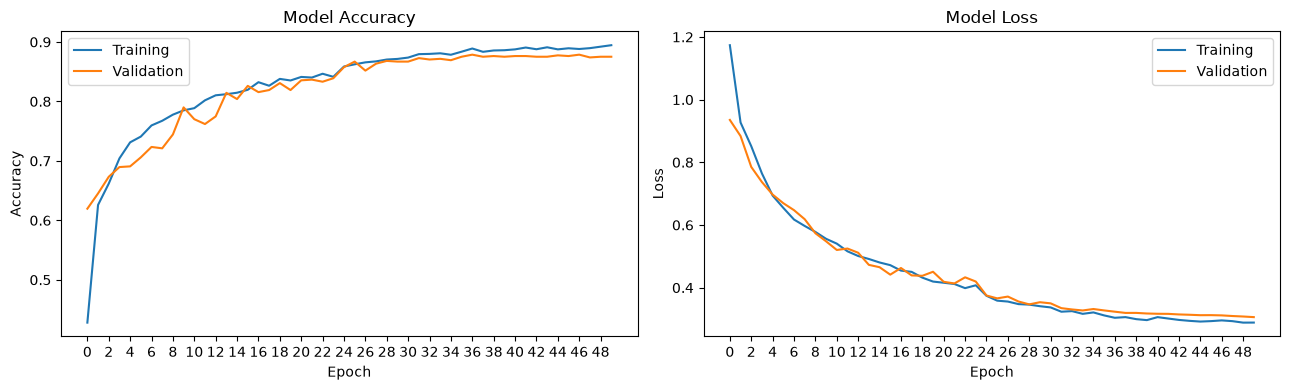

In [23]:

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_xticks(range(0, len(history.history["accuracy"]), 2))
axes[0].set_title("Model Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_xticks(range(0, len(history.history["accuracy"]), 2))
axes[1].set_title("Model Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()


In [24]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

41/41 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 0.8513 - loss: 0.3790
Test Loss: 0.3790
Test Accuracy: 85.13%


41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step


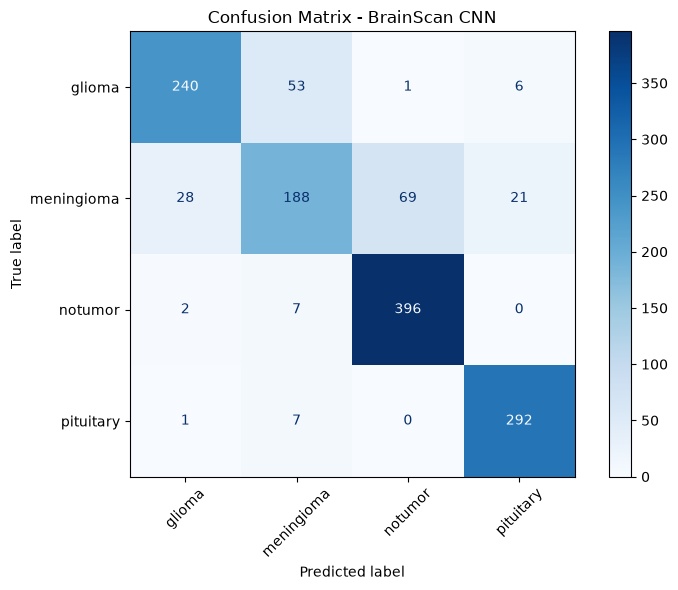

              precision    recall  f1-score   support

      glioma     0.8856    0.8000    0.8406       300
  meningioma     0.7373    0.6144    0.6702       306
     notumor     0.8498    0.9778    0.9093       405
   pituitary     0.9154    0.9733    0.9435       300

    accuracy                         0.8513      1311
   macro avg     0.8470    0.8414    0.8409      1311
weighted avg     0.8467    0.8513    0.8456      1311



In [ ]:
# Generate predictions for the test set
y_prob = model.predict(X_test, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Display the confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

fig, ax = plt.subplots(figsize=(8, 6))
display.plot(ax=ax, cmap="Blues", values_format="d")
plt.title("Confusion Matrix - BrainScan CNN")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Print classification report
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        digits=4,
        zero_division=0
    )
)

In [26]:
def predict_image(path):
    # Load the image
    image = cv2.imread(str(path))

    if image is None:
        raise ValueError(f"Could not read image: {path}")

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Apply the same preprocessing used during training
    image = resize_with_padding(image, IMAGE_SIZE)

    # Normalize pixel values to [0, 1]
    image = image.astype(np.float32) / 255.0

    # Add batch dimension: (224, 224, 3) -> (1, 224, 224, 3)
    image_batch = np.expand_dims(image, axis=0)

    # Predict class probabilities
    probabilities = model.predict(image_batch, verbose=0)[0]

    # Get the predicted class
    predicted_index = int(np.argmax(probabilities))
    predicted_class = label_encoder.inverse_transform([predicted_index])[0]

    # Display the image and probabilities
    plt.figure(figsize=(6, 5))
    plt.imshow(image)
    plt.title(f"Predicted class: {predicted_class}")
    plt.axis("off")
    plt.show()

    return predicted_class, probabilities

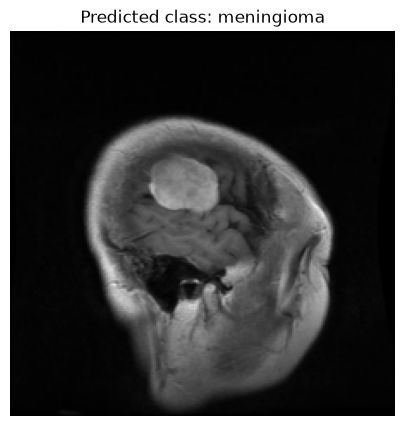

In [35]:
sample_path = DATA_DIR / "meningioma" / "Te-me_0235.jpg"

predicted_class, probabilities = predict_image(sample_path)